In [20]:
import openmc
import numpy as np
import matplotlib.pyplot as plt
import glob
from IPython.display import Image, display

# Initial Simulation
Gd2O3 powder with 98.2% Gd-160, 60% powder packing fraction, quartz support, surrounded by He, 1cm radius target, 0.4 cm target thickness


In [11]:
# MATERIALS

# Enriched Gd2O3 powder
Gd_oxide = openmc.Material(name="Enriched Gd2O3 powder")

# Isotopic Composition
Gd160_atom_percent = 0.982
Gd158_atom_percent = 0.018
Gd_oxide.add_nuclide("Gd160", 2*Gd160_atom_percent)
Gd_oxide.add_nuclide("Gd158", 2*Gd158_atom_percent)
Gd_oxide.add_nuclide("O16", 3)

# Effective density
solid_density = 7.4 #g/cc, approximate value
packing_fraction = 0.60
Gd_oxide.set_density("g/cm3", solid_density*packing_fraction)

# Quartz Support
quartz = openmc.Material(name="Quartz")
quartz.add_element("Si", 1)
quartz.add_element("O", 2)
quartz.set_density("g/cm3", 2.65)

# Surrounding He
He = openmc.Material(name="Helium")
He.add_nuclide("He4", 1)
He.set_density("g/cm3", 0.0001785)

materials = openmc.Materials([Gd_oxide, quartz, He])
materials.export_to_xml()

In [12]:
# GEOMETRY
target_radius = 1 #cm
target_bottom = 0 #cm
target_top = 0.4 #cm
support_bottom = -0.1 #cm

# Cylinder Boundary
cylinder = openmc.ZCylinder(r=target_radius)
z_bottom = openmc.ZPlane(z0=target_bottom)
z_top = openmc.ZPlane(z0=target_top)
z_support = openmc.ZPlane(z0=support_bottom)

# Outer Boundary
outer_sphere = openmc.Sphere(r=10, boundary_type="vacuum")
inside = -outer_sphere

# Gd2O3 Powder Bed
target_region = (-cylinder & +z_bottom & -z_top)
target_cell = openmc.Cell(name="Gd2O3 target", fill=Gd_oxide, region=target_region)

# Quartz Region
support_region = (-cylinder & +z_support & -z_bottom)
support_cell = openmc.Cell(name="quartz support", fill=quartz, region=support_region)

# Helium
He_cell = openmc.Cell(name="Helium Surroundings", fill=He, region=inside & ~target_region & ~support_region)

root = openmc.Universe(cells=[target_cell, support_cell, He_cell])
geometry = openmc.Geometry(root)

geometry.export_to_xml()

In [14]:
# NEUTRON SOURCE

settings = openmc.Settings()
settings.run_mode = "fixed source"

#Simplified thermal beam directed upward
source = openmc.IndependentSource()
source.space = openmc.stats.Box([-1,-1,-3],
                                [1,1,-2.999],
                                only_fissionable=False)
source.angle = openmc.stats.Monodirectional((0.0, 0.0, 1.0))

# Neutron Energy
neutron_energy = 0.0253 #eV
source.energy = openmc.stats.Discrete([neutron_energy], [1.0])

settings.source = source
settings.batches = 50
settings.particles = 10000

settings.export_to_xml()

In [15]:
# TALLIES
target_filter = openmc.CellFilter(target_cell)

# Neutron flux in target
flux_tally = openmc.Tally(name="target_flux")
flux_tally.filters = [target_filter]
flux_tally.scores = ["flux"]

# Neutron capture on Gd-160,158
capture_tally = openmc.Tally(name="Gd_capture")
capture_tally.filters = [target_filter]
capture_tally.nuclides = ["Gd160", "Gd158"]
capture_tally.scores = ["102"]

tallies = openmc.Tallies([flux_tally, capture_tally])
tallies.export_to_xml()

In [16]:
openmc.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [18]:
statepoint_file = sorted(glob.glob("statepoint.*.h5"))[-1]
sp = openmc.StatePoint(statepoint_file)
capture = sp.get_tally(name="Gd_capture")
flux = sp.get_tally(name="target_flux")
print("Gd capture tally:")
print(capture.get_pandas_dataframe())

print("\nTarget flux tally:")
print(flux.get_pandas_dataframe())

sp.close()

Gd capture tally:
   cell nuclide      score     mean  std. dev.
0     4   Gd160  (n,gamma) 6.54e-03   6.77e-06
1     4   Gd158  (n,gamma) 1.87e-04   1.94e-07

Target flux tally:
   cell nuclide score     mean  std. dev.
0     4   total  flux 3.24e-01   3.30e-04


/home/elijbomb/miniconda3/envs/openmc_env/lib/python3.14/site-packages/openmc/plots.py:1389: FutureWarning: The Plot class is deprecated. Use SlicePlot for 2D slice plots or VoxelPlot for 3D voxel plots.
  warnings.warn(


                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

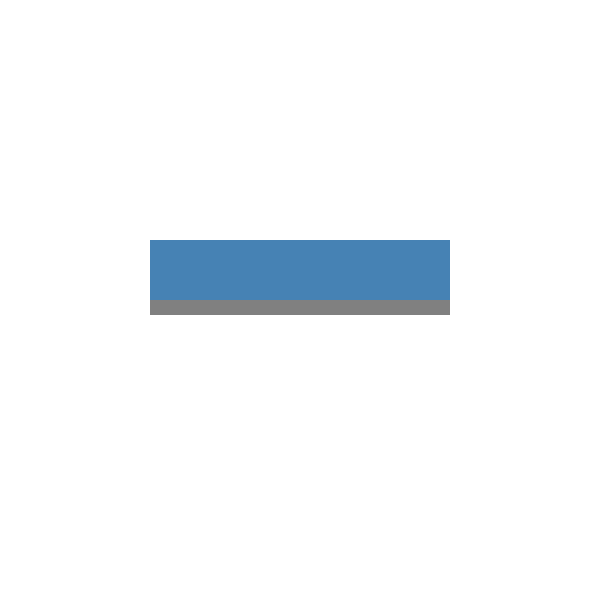

In [24]:
# XZ cross-section through the capsule
plot = openmc.Plot()
plot.basis = "xz"
plot.origin = (0, 0, 0)
plot.width = (4, 4)
plot.pixels = (600, 600)
plot.color_by = "material"
plot.colors = {Gd_oxide: "steelblue", quartz: "gray", He: "white"}
plots = openmc.Plots([plot])

plots.export_to_xml()
openmc.plot_geometry()
display(Image(filename="plot_1.png"))

In [23]:
# Neutron capture results
files = glob.glob("statepoint.*.h5")
print("Statepoint files:", files)
if files:
    with openmc.StatePoint(files[-1]) as sp:
        capture = sp.get_tally(name="Gd_capture")
        print(capture.get_pandas_dataframe())

Statepoint files: ['statepoint.50.h5']
   cell nuclide      score     mean  std. dev.
0     4   Gd160  (n,gamma) 6.54e-03   6.77e-06
1     4   Gd158  (n,gamma) 1.87e-04   1.94e-07
